# Task 4 – Web Log Analysis (Tutorial-aligned revision)

This notebook follows the CAB330 practicals **Loading Data** and **Cleaning web logs**: read raw log lines, parse fields, clean unwanted requests, identify sessions using the **30-minute timeout**, then perform simple Apriori association mining on page categories. It retains the useful image-path check from the previous notebook because this dataset contains extensionless image URLs.

**Run cells from top to bottom.** Set `LOG_FILE` to the location of `Dataset4Task4_26.txt`. The dataset is not embedded in this notebook.

## Q1. Read and parse the raw web logs

Use `open(...).readlines()` from the Loading Data practical; parse each line into the eleven attributes specified in the assessment. A regular expression is used because quoted user-agent strings contain spaces, making basic whitespace splitting unreliable.

In [4]:
import re
import pandas as pd
import matplotlib.pyplot as plt

LOG_FILE = 'CAB330_asm2_datasets 2/Dataset4Task4_26.txt'  # update if necessary
with open(LOG_FILE, 'r', encoding='utf-8') as file:
    web_logs = file.readlines()

print('Total raw lines:', len(web_logs))
print('First two raw lines:')
print(''.join(web_logs[:2]))

Total raw lines: 15000
First two raw lines:
54.36.149.41 - - [22/Jan/2019:03:56:14 +0330] "GET /filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA%A9%D8%B3%D9%84,27|%DA%A9%D9%85%D8%AA%D8%B1%20%D8%A7%D8%B2%205%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA%A9%D8%B3%D9%84,p53 HTTP/1.1" 200 30577 "-" "Mozilla/5.0 (compatible; AhrefsBot/6.1; +http://ahrefs.com/robot/)" "-"
31.56.96.51 - - [22/Jan/2019:03:56:16 +0330] "GET /image/60844/productModel/200x200 HTTP/1.1" 200 5667 "https://www.zanbil.ir/m/filter/b113" "Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build/HuaweiALE-L21) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/66.0.3359.158 Mobile Safari/537.36" "-"



In [5]:
# Standard combined-log fields, with optional extra quoted field at the end
pattern = re.compile(
    r'^(\S+) (\S+) (\S+) \[([^\]]+)\] "([^"]*)" (\S+) (\S+) "([^"]*)" "([^"]*)"(?: "[^"]*")?$'
)
rows = []
failed_lines = []
for line_number, line in enumerate(web_logs, start=1):
    match = pattern.match(line.strip())
    if not match:
        failed_lines.append(line_number)
        continue
    ip, ident, auth, time, request, status, size, referrer, user_agent = match.groups()
    request_parts = request.split()
    if len(request_parts) >= 3:
        method, proto = request_parts[0], request_parts[-1]
        path = ' '.join(request_parts[1:-1])
    else:
        method, path, proto = (request_parts + ['-', '-'])[:3]
    rows.append([ip, auth, ident, time, method, path, proto,
                 status, size, referrer, user_agent])

columns = ['ip', 'auth', 'ident', 'time', 'method', 'path', 'proto',
           'status', 'size', 'referrer', 'user_agent']
logs = pd.DataFrame(rows, columns=columns)
print('Parsed records:', len(logs), '| Unparsed lines:', len(failed_lines))
print('Unparsed line numbers (first 10):', failed_lines[:10])
display(logs.head(10))

Parsed records: 15000 | Unparsed lines: 0
Unparsed line numbers (first 10): []


,ip,auth,ident,time,method,path,proto,status,size,referrer,user_agent
0,54.36.149.41,-,-,22/Jan/2019:03:56:14 +0330,GET,/filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C...,HTTP/1.1,200,30577,-,Mozilla/5.0 (compatible; AhrefsBot/6.1; +http:...
1,31.56.96.51,-,-,22/Jan/2019:03:56:16 +0330,GET,/image/60844/productModel/200x200,HTTP/1.1,200,5667,https://www.zanbil.ir/m/filter/b113,Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build...
2,31.56.96.51,-,-,22/Jan/2019:03:56:16 +0330,GET,/image/61474/productModel/200x200,HTTP/1.1,200,5379,https://www.zanbil.ir/m/filter/b113,Mozilla/5.0 (Linux; Android 6.0; ALE-L21 Build...
3,40.77.167.129,-,-,22/Jan/2019:03:56:17 +0330,GET,/image/14925/productModel/100x100,HTTP/1.1,200,1696,-,Mozilla/5.0 (compatible; bingbot/2.0; +http://...
4,91.99.72.15,-,-,22/Jan/2019:03:56:17 +0330,GET,/product/31893/62100/%D8%B3%D8%B4%D9%88%D8%A7%...,HTTP/1.1,200,41483,-,Mozilla/5.0 (Windows NT 6.2; Win64; x64; rv:16...
5,40.77.167.129,-,-,22/Jan/2019:03:56:17 +0330,GET,/image/23488/productModel/150x150,HTTP/1.1,200,2654,-,Mozilla/5.0 (compatible; bingbot/2.0; +http://...
6,40.77.167.129,-,-,22/Jan/2019:03:56:18 +0330,GET,/image/45437/productModel/150x150,HTTP/1.1,200,3688,-,Mozilla/5.0 (compatible; bingbot/2.0; +http://...
7,40.77.167.129,-,-,22/Jan/2019:03:56:18 +0330,GET,/image/576/article/100x100,HTTP/1.1,200,14776,-,Mozilla/5.0 (compatible; bingbot/2.0; +http://...
8,66.249.66.194,-,-,22/Jan/2019:03:56:18 +0330,GET,"/filter/b41,b665,c150%7C%D8%A8%D8%AE%D8%A7%D8%...",HTTP/1.1,200,34277,-,Mozilla/5.0 (compatible; Googlebot/2.1; +http:...
9,40.77.167.129,-,-,22/Jan/2019:03:56:18 +0330,GET,/image/57710/productModel/100x100,HTTP/1.1,200,1695,-,Mozilla/5.0 (compatible; bingbot/2.0; +http://...


## Q2. Clean data and sort by datetime

The practical converts dates, removes fields not needed for web usage analysis, and sorts by time. In this log, `-` means missing. We retain `user_agent` until Q5 to identify obvious crawlers; the main session output uses only the required columns.

In [6]:
# Convert time and status to appropriate data types
logs['Datetime'] = pd.to_datetime(
    logs['time'], format='%d/%b/%Y:%H:%M:%S %z', errors='coerce', utc=True
)
logs['status'] = pd.to_numeric(logs['status'], errors='coerce')

print('Missing indicators in original fields:')
print((logs[columns] == '-').sum())
print('Invalid date/time:', logs['Datetime'].isna().sum())

# Drop unnecessary original columns; user_agent kept temporarily for crawler analysis
cleaned = logs.drop(columns=['time', 'ident', 'auth', 'size', 'referrer']).copy()
cleaned = cleaned.dropna(subset=['Datetime', 'status'])
cleaned = cleaned[cleaned['ip'].ne('-') & cleaned['path'].ne('-')]
cleaned['status'] = cleaned['status'].astype(int)
cleaned = cleaned.sort_values('Datetime', ascending=False).reset_index(drop=True)
print('Rows after basic cleaning:', len(cleaned))
display(cleaned[['ip','method','path','proto','status','Datetime']].head(10))

Missing indicators in original fields:
ip                0
auth          15000
ident         15000
time              0
method            0
path              0
proto             0
status            0
size              0
referrer       8234
user_agent      109
dtype: int64
Invalid date/time: 0
Rows after basic cleaning: 15000


,ip,method,path,proto,status,Datetime
0,146.185.133.111,GET,/image/60701/productModel/200x200,HTTP/1.1,200,2019-01-22 01:26:13+00:00
1,146.185.133.111,GET,/image/61956/productModel/200x200,HTTP/1.1,200,2019-01-22 01:26:13+00:00
2,207.46.13.136,GET,/filter?f=b2%2Cb484%2Cp1&o=b,HTTP/1.1,302,2019-01-22 01:26:13+00:00
3,91.99.72.15,GET,/product/31055?model=60906,HTTP/1.1,200,2019-01-22 01:26:13+00:00
4,207.46.13.136,GET,"/filter/b238,b613,b723",HTTP/1.1,200,2019-01-22 01:26:12+00:00
5,54.36.149.13,GET,/filter/p11673%2Cv1%7C%D8%A2%D8%A8%DB%8C%20%D9...,HTTP/1.1,302,2019-01-22 01:26:12+00:00
6,108.26.219.129,GET,/apple-touch-icon-120x120.png,HTTP/1.1,404,2019-01-22 01:26:12+00:00
7,66.249.66.194,GET,/m/browse/pens-and-pencell/%D9%82%D9%84%D9%85,HTTP/1.1,200,2019-01-22 01:26:12+00:00
8,108.26.219.129,GET,/apple-touch-icon-precomposed.png,HTTP/1.1,404,2019-01-22 01:26:12+00:00
9,40.77.167.170,GET,"/filter/b18,p31385",HTTP/1.1,200,2019-01-22 01:26:12+00:00


## Q3. Remove image and audio requests

The Cleaning web logs practical filters `.gif`, `.jpg` and `.jpeg`. Here we keep that **same masking approach**, extended just enough for dataset-specific image routes such as `/image/60844/productModel/200x200`, which have no file extension. Count the removed rows **before** applying the mask. The assignment explicitly asks to remove image and audio requests, so we do not remove non-200 status codes unless separately justified.

In [7]:
# Path without query string; lower case for case-insensitive checks
path_lower = cleaned['path'].fillna('').str.split('?', n=1).str[0].str.lower()

# Image/audio extensions, as in the practical (plus common newer extensions)
image_extension = path_lower.str.contains(r'\.(?:gif|jpe?g|png|webp|svg|bmp|ico)$', regex=True)
audio_extension = path_lower.str.contains(r'\.(?:mp3|wav|ogg|oga|aac|m4a|flac|wma)$', regex=True)

# This dataset also uses extensionless image endpoints; do not treat e.g.
# /product/audio-and-video as audio unless it is really an audio endpoint.
image_route = path_lower.str.contains(r'/(?:image|images|productimage)(?:/|$)', regex=True)
image_route |= path_lower.str.contains(r'^/settings/logo(?:/|$)', regex=True)
image_route |= path_lower.str.contains(r'(?:^|/)apple-touch-icon(?:[^/]*)$', regex=True)
audio_route = path_lower.str.contains(r'/(?:audio|sound|mp3)(?:/|$)', regex=True)

image_mask = image_extension | image_route
audio_mask = (audio_extension | audio_route) & ~image_mask
print('Image request rows:', int(image_mask.sum()))
print('Audio request rows:', int(audio_mask.sum()))

pages = cleaned.loc[~(image_mask | audio_mask)].copy()
print('Rows remaining after media removal:', len(pages))
display(pages[['ip','method','path','proto','status','Datetime']].head(10))

Image request rows: 6780
Audio request rows: 0
Rows remaining after media removal: 8220


,ip,method,path,proto,status,Datetime
2,207.46.13.136,GET,/filter?f=b2%2Cb484%2Cp1&o=b,HTTP/1.1,302,2019-01-22 01:26:13+00:00
3,91.99.72.15,GET,/product/31055?model=60906,HTTP/1.1,200,2019-01-22 01:26:13+00:00
4,207.46.13.136,GET,"/filter/b238,b613,b723",HTTP/1.1,200,2019-01-22 01:26:12+00:00
5,54.36.149.13,GET,/filter/p11673%2Cv1%7C%D8%A2%D8%A8%DB%8C%20%D9...,HTTP/1.1,302,2019-01-22 01:26:12+00:00
7,66.249.66.194,GET,/m/browse/pens-and-pencell/%D9%82%D9%84%D9%85,HTTP/1.1,200,2019-01-22 01:26:12+00:00
9,40.77.167.170,GET,"/filter/b18,p31385",HTTP/1.1,200,2019-01-22 01:26:12+00:00
17,91.99.72.15,GET,/product/29846?model=59351,HTTP/1.1,200,2019-01-22 01:26:11+00:00
19,66.249.66.194,GET,"/m/filter/,b141,b186,b192,b3,b33,t143,t156,t18...",HTTP/1.1,200,2019-01-22 01:26:11+00:00
24,66.249.66.91,GET,/filter/b481%2Cb43%2Cb874%2Cb32%2Cb67%2Cb36%2C...,HTTP/1.1,200,2019-01-22 01:26:10+00:00
25,207.46.13.136,GET,"/filter/b1,b141,b169,b36,b820",HTTP/1.1,200,2019-01-22 01:26:10+00:00


## Q4. Identify sessions and navigation steps

**Definition:** A session consists of requests from the same IP on the same calendar day where consecutive requests are no more than **30 minutes apart**. A new session starts when the IP/day changes or the gap since the previous request exceeds 30 minutes. This follows the tutorial's IP + date + timeout rule.

IP is only an approximation of a user: shared networks, changing IP addresses and crawlers may affect the results. Sort chronologically *before* assigning the step numbers.

In [8]:
# Same session definition as the practical, expressed with simple pandas grouping
pages = pages.sort_values(['Datetime', 'ip'], kind='mergesort').reset_index(drop=True)
pages['Date'] = pages['Datetime'].dt.date

# Difference from the preceding request for the SAME IP on the SAME day
previous_time = pages.groupby(['Date', 'ip'])['Datetime'].diff()
pages['NewSession'] = previous_time.isna() | (previous_time > pd.Timedelta(minutes=30))

# Globally unique numeric session IDs, in chronological first-appearance order
pages['SessionID'] = pages['NewSession'].cumsum().astype(int)
# Fix IDs for interleaved IPs: requests in same IP/day session share an ID
pages['LocalSession'] = pages.groupby(['Date', 'ip'])['NewSession'].cumsum()
pages['SessionID'] = pages.groupby(['Date','ip','LocalSession'], sort=False).ngroup() + 1
pages['Steps'] = pages.groupby('SessionID').cumcount() + 1

print('Number of sessions:', pages['SessionID'].nunique())
print('Page/document requests:', len(pages))
print('Requests per session:')
print(pages.groupby('SessionID').size().describe())

# Display like the task specification
session_table = pages[['ip','method','path','proto','status','Datetime','SessionID','Steps']]
display(session_table.head(15))

Number of sessions: 602
Page/document requests: 8220
Requests per session:
count     602.000000
mean       13.654485
std       102.987586
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max      2018.000000
dtype: float64


,ip,method,path,proto,status,Datetime,SessionID,Steps
0,54.36.149.41,GET,/filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C...,HTTP/1.1,200,2019-01-22 00:26:14+00:00,1,1
1,91.99.72.15,GET,/product/31893/62100/%D8%B3%D8%B4%D9%88%D8%A7%...,HTTP/1.1,200,2019-01-22 00:26:17+00:00,2,1
2,207.46.13.136,GET,/product/10214,HTTP/1.1,200,2019-01-22 00:26:18+00:00,3,1
3,66.249.66.194,GET,"/filter/b41,b665,c150%7C%D8%A8%D8%AE%D8%A7%D8%...",HTTP/1.1,200,2019-01-22 00:26:18+00:00,4,1
4,178.253.33.51,GET,/m/product/32574/62991/%D9%85%D8%A7%D8%B4%DB%8...,HTTP/1.1,200,2019-01-22 00:26:19+00:00,5,1
5,207.46.13.136,GET,/product/14926,HTTP/1.1,404,2019-01-22 00:26:19+00:00,3,2
6,91.99.72.15,GET,/product/10075/13903/%D9%85%D8%A7%DB%8C%DA%A9%...,HTTP/1.1,200,2019-01-22 00:26:19+00:00,2,2
7,66.249.66.194,GET,"/m/filter/b2,p6",HTTP/1.1,200,2019-01-22 00:26:20+00:00,4,2
8,66.249.66.91,GET,/filter/b874%2Cb32%2Cb63%2Cb99%2Cb126%2Cb820%2...,HTTP/1.1,200,2019-01-22 00:26:20+00:00,6,1
9,91.99.72.15,GET,/product/32798/63266/%DB%8C%D8%AE%DA%86%D8%A7%...,HTTP/1.1,200,2019-01-22 00:26:20+00:00,2,3


## Q5. Association mining of page categories

**Method:** Apriori, as in the association-mining practical. A browsing session is treated as a transaction (basket); page **categories**, not unique product URL IDs, are the items. This helps identify page types appearing together and can inform site navigation decisions.

**Features:** `SessionID` groups requests into baskets and `path` provides the page category. `Datetime` and `ip` were used for session identification. We exclude obvious crawler requests **only for this behaviour-focused analysis**, retaining all requests in Q4's required session table. The filtering is approximate.

**Mobile and desktop handling:** A path such as `/m/product/456` and `/product/123` are both treated as the category `product`. We are analysing page types, not device-specific browsing patterns. The original URL remains in the `path` column.


In [9]:
%pip install apyori

Note: you may need to restart the kernel to use updated packages.


In [10]:
from apyori import apriori

# Extract general page categories. Treat mobile and desktop URLs alike.
page_types = {'product','filter','browse','blog','search','basket','login',
              'customer','article','comparison','order'}

def page_family(path):
    segments = [x.lower() for x in str(path).split('?', 1)[0].split('/') if x]
    if not segments or segments[0] in ('index', 'index.php'):
        return 'home'
    if segments[0] == 'm':
        return segments[1] if len(segments) > 1 and segments[1] in page_types else None
    return segments[0] if segments[0] in page_types else None

pages['PageType'] = pages['path'].apply(page_family)
bot_terms = r'bot|spider|crawler|slurp|ahrefs|semrush|dotbot|yandex|baidu|sogou'
pages['IsCrawler'] = pages['user_agent'].fillna('').str.contains(bot_terms, case=False, regex=True)

print('Requests with known page categories:', pages['PageType'].notna().sum())
print('Identified crawler requests:', pages['IsCrawler'].sum())
display(pages['PageType'].value_counts())

# A transaction is a unique list of page categories appearing in one session.
# Omit obvious crawler sessions for the customer-oriented example.
human_sessions = pages.groupby('SessionID')['IsCrawler'].mean()
human_session_ids = human_sessions[human_sessions < 0.5].index
human_pages = pages[pages['SessionID'].isin(human_session_ids)].dropna(subset=['PageType'])
transactions = human_pages.groupby('SessionID')['PageType'].apply(lambda x: sorted(set(x)))
transaction_list = list(transactions)
print('Sessions with at least one category:', len(transaction_list))
print('Example session baskets:')
print(transaction_list[:10])

Requests with known page categories: 7414
Identified crawler requests: 5570


PageType
filter        4963
product       1416
browse         386
home           247
blog           174
article         83
search          57
basket          30
customer        29
login           20
comparison       7
order            2
Name: count, dtype: int64

Sessions with at least one category: 135
Example session baskets:
[['product'], ['product'], ['filter', 'product'], ['home'], ['browse', 'filter', 'product'], ['browse', 'filter', 'product'], ['blog'], ['browse', 'filter', 'product'], ['filter', 'search'], ['browse', 'comparison', 'filter', 'product']]


In [11]:
# Same algorithm and output format as the Apriori tutorial
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.10
if len(transaction_list) == 0:
    raise ValueError('No session baskets; inspect the selected page types and input log.')
results = list(apriori(transaction_list,
                      min_support=MIN_SUPPORT,
                      min_confidence=MIN_CONFIDENCE))

rules = []
for rule_set in results:
    for rule in rule_set.ordered_statistics:
        if rule.items_base and rule.items_add:
            rules.append([
                ','.join(sorted(rule.items_base)),
                ','.join(sorted(rule.items_add)),
                rule_set.support, rule.confidence, rule.lift
            ])

rule_df = pd.DataFrame(rules, columns=['Left_side','Right_side',
                                      'Support','Confidence','Lift'])
rule_df = rule_df.sort_values(['Lift','Confidence'], ascending=False).reset_index(drop=True)
print('Association rules:', len(rule_df))
display(rule_df.head(20))

Association rules: 27


,Left_side,Right_side,Support,Confidence,Lift
0,"filter,home",browse,0.022222,1.000000,3.292683
1,search,"browse,filter",0.029630,0.500000,3.214286
2,"browse,filter",search,0.029630,0.190476,3.214286
3,"browse,search",filter,0.029630,1.000000,2.700000
4,"filter,search",browse,0.029630,0.666667,2.195122
5,basket,product,0.022222,1.000000,2.177419
6,search,filter,0.044444,0.750000,2.025000
7,"browse,home",filter,0.022222,0.750000,2.025000
8,"browse,product",filter,0.111111,0.750000,2.025000
9,filter,"browse,product",0.111111,0.300000,2.025000


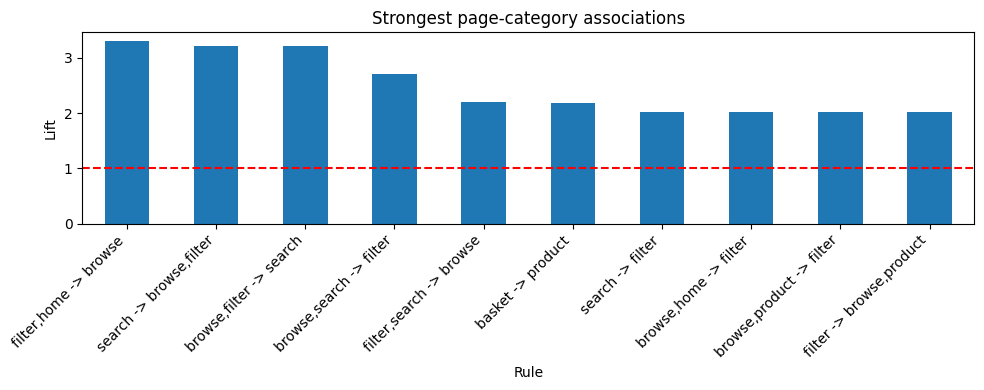

In [12]:
# Simple visual summary, without the extra plotting pipelines in the old notebook
if not rule_df.empty:
    top_rules = rule_df.head(10).copy()
    top_rules['Rule'] = top_rules['Left_side'] + ' -> ' + top_rules['Right_side']
    top_rules.plot(x='Rule', y='Lift', kind='bar', figsize=(10, 4), legend=False)
    plt.axhline(1, color='red', linestyle='--')
    plt.ylabel('Lift')
    plt.title('Strongest page-category associations')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print('No association rules at these thresholds. Report this rather than inventing results.')

### Q5 case-study discussion (complete after running)

Choose an association rule with **lift > 1** from the table above. Explain its support, confidence and lift, then propose a navigation improvement (for example, a more visible link between associated categories). The dataset is observational: the rule indicates co-occurrence, **not that adding a link will cause a sales increase**. Any change should be tested with a site experiment.

**Limitations:** IP-based sessions are approximate; some crawlers may not identify themselves, and dynamic URLs or unrecognised page routes are not treated as page categories. Avoid treating the task specification's *example* session IDs as expected exact values for this dataset.